In [ ]:
import pandas as pd
import io

# 1. Cargar el dataset
# Se usa 'sep=";"' porque el archivo usa punto y coma como delimitador
df = pd.read_csv('world_happiness_combined.csv', sep=';')

# 2. Estandarizar nombres de columnas
# Convertimos a minúsculas y reemplazamos espacios por guiones bajos para facilitar el uso
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# 3. Convertir comas a puntos y cambiar a tipo numérico (Float)
# Identificamos las columnas que deberían ser numéricas pero se leyeron como texto por la coma
columnas_numericas = [
    'happiness_score', 'gdp_per_capita', 'social_support',
    'healthy_life_expectancy', 'freedom_to_make_life_choices',
    'generosity', 'perceptions_of_corruption'
]

for col in columnas_numericas:
    # Verificamos si la columna es de tipo objeto (texto) antes de limpiar
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 4. Verificar y eliminar duplicados (si existen)
df = df.drop_duplicates()

# 5. Muestra de los datos limpios
print("Información del Dataset Limpio:")
print(df.info())
print("\nPrimeras 5 filas:")
print(df.head())

Información del Dataset Limpio:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1502 entries, 0 to 1501
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ranking                       1502 non-null   int64  
 1   country                       1502 non-null   object 
 2   regional_indicator            1499 non-null   object 
 3   happiness_score               1502 non-null   float64
 4   gdp_per_capita                1502 non-null   float64
 5   social_support                1502 non-null   float64
 6   healthy_life_expectancy       1502 non-null   int64  
 7   freedom_to_make_life_choices  1502 non-null   float64
 8   generosity                    1502 non-null   float64
 9   perceptions_of_corruption     1502 non-null   float64
 10  year                          1502 non-null   int64  
dtypes: float64(6), int64(3), object(2)
memory usage: 129.2+ KB
None

Primeras 5 filas:
   ran

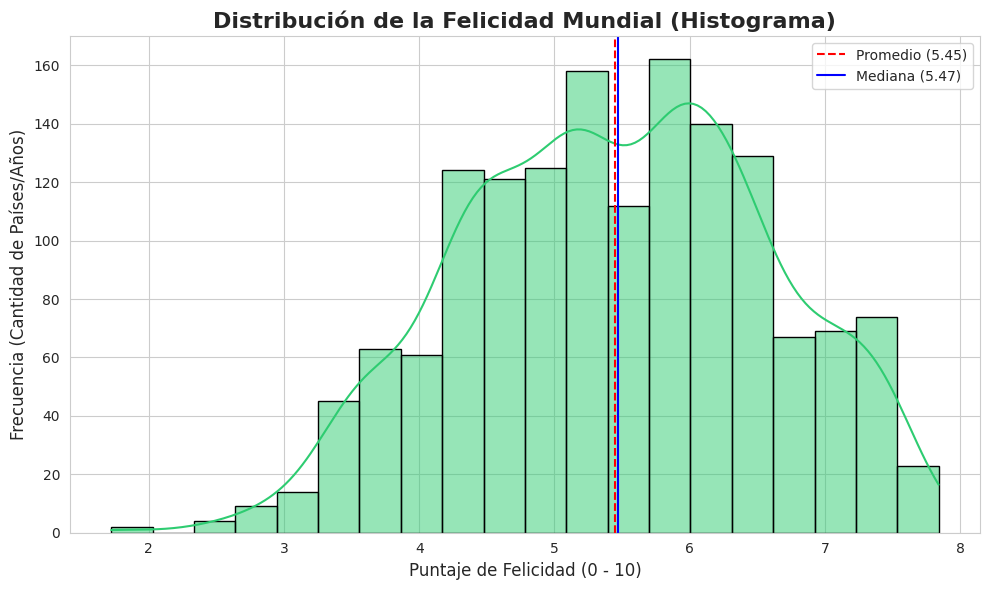

ANÁLISIS DE REPETICIONES:
- El puntaje de felicidad más frecuente (redondeado) es: 5.2
- La región que más aparece en los datos es: Sub-Saharan Africa


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset
df = pd.read_csv('world_happiness_combined.csv', sep=';')

# 2. Limpieza básica (igual que vimos antes)
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Lista de columnas que necesitan conversión de ',' a '.'
cols_numericas = [
    'happiness_score', 'gdp_per_capita', 'social_support',
    'healthy_life_expectancy', 'freedom_to_make_life_choices',
    'generosity', 'perceptions_of_corruption'
]

for col in cols_numericas:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 3. Crear el Histograma
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Usamos bins=20 para agrupar mejor los puntajes
sns.histplot(df['happiness_score'], bins=20, kde=True, color='#2ecc71', edgecolor='black')

plt.title('Distribución de la Felicidad Mundial (Histograma)', fontsize=16, fontweight='bold')
plt.xlabel('Puntaje de Felicidad (0 - 10)', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de Países/Años)', fontsize=12)

# Líneas de referencia
media = df['happiness_score'].mean()
mediana = df['happiness_score'].median()
plt.axvline(media, color='red', linestyle='--', label=f'Promedio ({media:.2f})')
plt.axvline(mediana, color='blue', linestyle='-', label=f'Mediana ({mediana:.2f})')

plt.legend()
plt.tight_layout()
plt.show()

# 4. Calcular métricas que más se repiten (Moda)
# Redondeamos a 1 decimal para encontrar "agrupaciones" comunes, ya que los exactos casi no se repiten
moda_puntaje = df['happiness_score'].round(1).mode()[0]
frecuencia_moda = df[df['happiness_score'].round(1) == moda_puntaje].shape[0]

region_top = df['regional_indicator'].mode()[0]
frecuencia_region = df['regional_indicator'].value_counts().max()

print(f"ANÁLISIS DE REPETICIONES:")
print(f"- El puntaje de felicidad más frecuente (redondeado) es: {moda_puntaje}")
print(f"- La región que más aparece en los datos es: {region_top}")

In [ ]:
!pip -q install pycountry plotly


import pandas as pd
import numpy as np
import pycountry
import plotly.express as px

# --- Asegurar columnas ---
assert "country" in df.columns, "No existe la columna 'country'"
assert "happiness_score" in df.columns, "No existe la columna 'happiness_score'"

# --- Elegir cómo agregas felicidad por país ---
# Opción A: usar el ÚLTIMO AÑO disponible (si existe 'year')
USE_LATEST_YEAR = True

if USE_LATEST_YEAR and "year" in df.columns:
    latest_year = int(df["year"].max())
    df_use = df[df["year"] == latest_year].copy()
    title_suffix = f"(Último año: {latest_year})"
else:
    df_use = df.copy()
    title_suffix = "(Promedio de todos los años)"

# --- Agregar por país (promedio) ---
country_score = (
    df_use.groupby("country", as_index=False)["happiness_score"]
    .mean()
    .rename(columns={"happiness_score": "happiness_mean"})
)

# --- Función para convertir Country name -> ISO3 ---
# (maneja varios casos comunes que suelen romper)
MANUAL_FIXES = {
    "United States": "United States of America",
    "Russia": "Russian Federation",
    "Congo (Brazzaville)": "Congo",
    "Congo (Kinshasa)": "Congo, The Democratic Republic of the",
    "Iran": "Iran, Islamic Republic of",
    "Vietnam": "Viet Nam",
    "Syria": "Syrian Arab Republic",
    "Tanzania": "Tanzania, United Republic of",
    "Bolivia": "Bolivia, Plurinational State of",
    "Venezuela": "Venezuela, Bolivarian Republic of",
    "Palestine": "Palestine, State of",
    "Laos": "Lao People's Democratic Republic",
    "South Korea": "Korea, Republic of",
    "North Korea": "Korea, Democratic People's Republic of",
    "Moldova": "Moldova, Republic of",
    "Czech Republic": "Czechia",
    "Cape Verde": "Cabo Verde",
    "Swaziland": "Eswatini",
    "Ivory Coast": "Côte d'Ivoire",
    "Myanmar": "Myanmar",
    "Brunei": "Brunei Darussalam",
}

def to_iso3(name: str):
    if pd.isna(name):
        return None
    name2 = MANUAL_FIXES.get(name, name)
    try:
        return pycountry.countries.lookup(name2).alpha_3
    except Exception:
        return None

country_score["iso3"] = country_score["country"].apply(to_iso3)

# --- Ver qué países no pudieron mapearse ---
missing = country_score[country_score["iso3"].isna()][["country"]]
print("Países sin ISO3:", len(missing))
if len(missing) > 0:
    display(missing.head(20))

# --- Filtrar solo los que sí tienen ISO3 ---
plot_df = country_score.dropna(subset=["iso3"]).copy()

# --- Top 10 países más felices ---
top10 = plot_df.sort_values("happiness_mean", ascending=False).head(10)
print("\nTop 10 países más felices", title_suffix)
display(top10[["country", "happiness_mean"]])

# --- Mapa ---
fig = px.choropleth(
    plot_df,
    locations="iso3",
    color="happiness_mean",
    hover_name="country",
    color_continuous_scale="Viridis",
    title=f"Mapa mundial de felicidad {title_suffix}",
)

fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 47.3 MB/s eta 0:00:00
Países sin ISO3: 4


,country
2,Argelia
66,Kosovo
122,Taiwan Province of China
127,Turkiye



Top 10 países más felices (Último año: 2024)


,country,happiness_mean
39,Finland,7.7407
31,Denmark,7.5827
52,Iceland,7.5251
120,Sweden,7.3441
58,Israel,7.3411
93,Netherlands,7.3194
99,Norway,7.3017
76,Luxembourg,7.1219
121,Switzerland,7.0602
5,Australia,7.0569


In [ ]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza (Mismo proceso para asegurar consistencia)
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Convertir de ',' a '.' y a float
if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# Usaremos los datos del último año disponible (2024) para que sea actual
latest_year = df['year'].max()
df_latest = df[df['year'] == latest_year].copy()

# 2. Agrupar por Región para obtener el promedio
region_stats = (
    df_latest.groupby("regional_indicator", as_index=False)["happiness_score"]
    .mean()
    .sort_values("happiness_score", ascending=False)
)

# 3. Visualización 1: Ranking de Regiones (Barras)
fig_bar = px.bar(
    region_stats,
    x="happiness_score",
    y="regional_indicator",
    orientation='h',
    title=f"Ranking de Felicidad por Región ({latest_year})",
    color="happiness_score",
    color_continuous_scale="Viridis",
    labels={"happiness_score": "Promedio de Felicidad", "regional_indicator": "Región"}
)
fig_bar.show()

# 4. Visualización 2: Dispersión por Región (Boxplot)
# Esto nos permite ver si en una región todos son felices o si hay mucha desigualdad
fig_box = px.box(
    df_latest,
    x="regional_indicator",
    y="happiness_score",
    color="regional_indicator",
    title=f"Distribución y Desigualdad de la Felicidad por Región ({latest_year})",
    points="all", # Muestra los puntos de cada país sobre la caja
    hover_name="country"
)
fig_box.update_layout(xaxis_tickangle=-45, showlegend=False)
fig_box.show()

In [ ]:
import pandas as pd
import plotly.express as px

# 1. Cargar el dataset con el delimitador correcto
df = pd.read_csv('world_happiness_combined.csv', sep=';')

# 2. Limpieza de nombres de columnas y conversión de datos
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Convertir el puntaje de felicidad a número (manejando la coma decimal)
if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# 3. Filtrar por el año más reciente (2024)
ultimo_año = df['year'].max()
df_reciente = df[df['year'] == ultimo_año]

# 4. Obtener los extremos
top_10 = df_reciente.nlargest(10, 'happiness_score')
bottom_10 = df_reciente.nsmallest(10, 'happiness_score')

# Combinar ambos para una sola visualización
extremos = pd.concat([top_10, bottom_10]).sort_values('happiness_score', ascending=True)

# 5. Crear el gráfico con Plotly
fig = px.bar(
    extremos,
    x='happiness_score',
    y='country',
    orientation='h',
    color='happiness_score',
    title=f"Top 10 y Bottom 10: Países por Índice de Felicidad ({ultimo_año})",
    labels={'happiness_score': 'Puntaje de Felicidad', 'country': 'País'},
    color_continuous_scale='RdYlGn', # De rojo (infeliz) a verde (feliz)
    text='happiness_score'
)

fig.update_traces(texttemplate='%{text:.2f}', textposition='outside')
fig.update_layout(yaxis={'categoryorder':'total ascending'}, height=700, template="plotly_white")
fig.show()

# Mostrar tablas rápidas en consola
print(f"--- TOP 10 MÁS FELICES ({ultimo_año}) ---")
print(top_10[['country', 'happiness_score']].reset_index(drop=True))
print(f"\n--- 10 MENOS FELICES ({ultimo_año}) ---")
print(bottom_10[['country', 'happiness_score']].sort_values('happiness_score').reset_index(drop=True))

--- TOP 10 MÁS FELICES (2024) ---
       country  happiness_score
0      Finland           7.7407
1      Denmark           7.5827
2      Iceland           7.5251
3       Sweden           7.3441
4       Israel           7.3411
5  Netherlands           7.3194
6       Norway           7.3017
7   Luxembourg           7.1219
8  Switzerland           7.0602
9    Australia           7.0569

--- 10 MENOS FELICES (2024) ---
            country  happiness_score
0       Afghanistan           1.7210
1           Lebanon           2.7065
2           Lesotho           3.1862
3      Sierra Leone           3.2452
4  Congo (Kinshasa)           3.2954
5          Zimbabwe           3.3411
6          Botswana           3.3834
7            Malawi           3.4210
8          Eswatini           3.5020
9            Zambia           3.5024


In [ ]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza rápida
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Limpiar las columnas numéricas (comas por puntos)
cols_to_fix = ['happiness_score', 'gdp_per_capita']
for col in cols_to_fix:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Filtrar por el año 2024 para tener la foto actual
df_2024 = df[df['year'] == 2024].copy()

# 3. Crear Gráfica de Dispersión
fig = px.scatter(
    df_2024,
    x="gdp_per_capita",
    y="happiness_score",
    color="regional_indicator",  # Colorear por región para ver patrones
    hover_name="country",        # Ver el nombre del país al pasar el mouse
    size="happiness_score",      # El tamaño de la burbuja depende de la felicidad
    trendline="ols",             # Agregamos una línea de tendencia (regresión lineal)
    title="¿El dinero compra la felicidad? (PIB vs Felicidad 2024)",
    labels={
        "gdp_per_capita": "Riqueza (PIB per cápita)",
        "happiness_score": "Puntaje de Felicidad",
        "regional_indicator": "Región"
    },
    template="plotly_white"
)

fig.show()

# Calcular la correlación matemática
correlacion = df_2024['gdp_per_capita'].corr(df_2024['happiness_score'])
print(f"La correlación entre riqueza y felicidad es de: {correlacion:.2f}")

La correlación entre riqueza y felicidad es de: 0.77


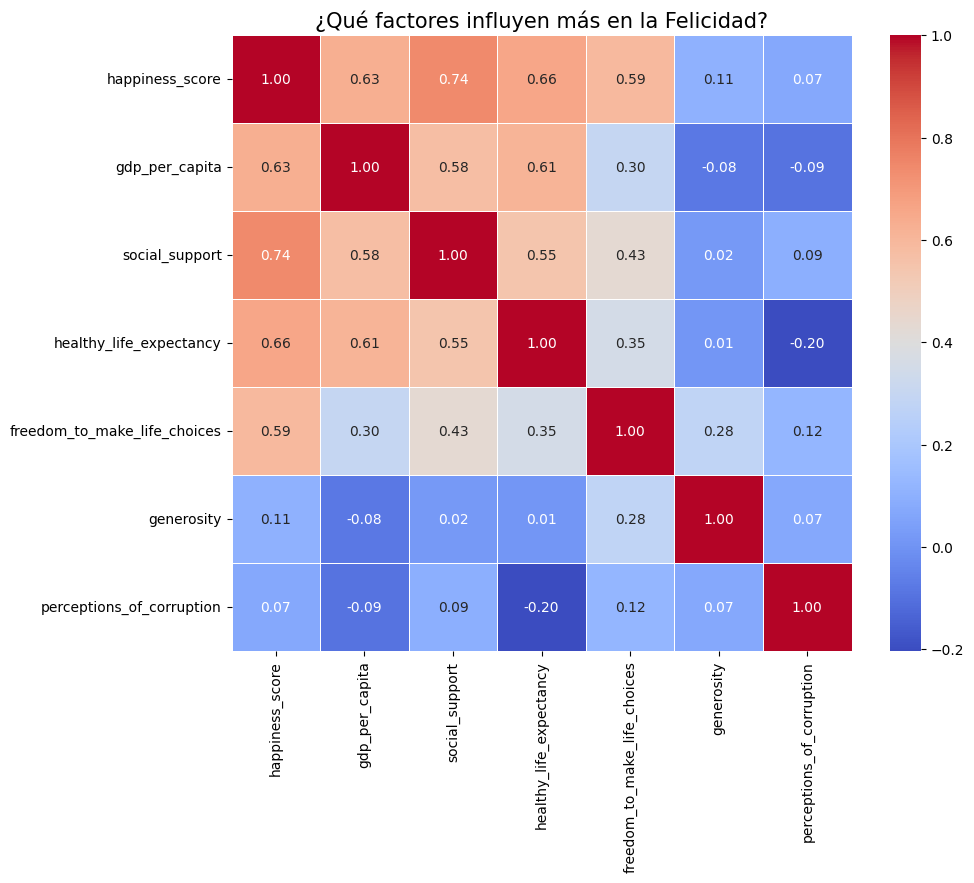

Correlación con el Puntaje de Felicidad (de mayor a menor):
happiness_score                 1.000000
social_support                  0.744092
healthy_life_expectancy         0.659959
gdp_per_capita                  0.631353
freedom_to_make_life_choices    0.591207
generosity                      0.105558
perceptions_of_corruption       0.071776
Name: happiness_score, dtype: float64


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Preparación de datos (limpieza ya conocida)
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

cols_num = [
    'happiness_score', 'gdp_per_capita', 'social_support',
    'healthy_life_expectancy', 'freedom_to_make_life_choices',
    'generosity', 'perceptions_of_corruption'
]

for col in cols_num:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Calcular la correlación
# Filtramos solo las columnas numéricas relevantes
corr_matrix = df[cols_num].corr()

# 3. Graficar el Mapa de Calor
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('¿Qué factores influyen más en la Felicidad?', fontsize=15)
plt.show()

# 4. Mostrar el ranking de factores que más correlacionan con la felicidad
print("Correlación con el Puntaje de Felicidad (de mayor a menor):")
print(corr_matrix['happiness_score'].sort_values(ascending=False))

In [2]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

cols_num = ['happiness_score']
for col in cols_num:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Agrupación por Año (Promedio Global)
global_trend = df.groupby('year')['happiness_score'].mean().reset_index()

# 3. Agrupación por Año y Región (Para ver detalles)
regional_trend = df.groupby(['year', 'regional_indicator'])['happiness_score'].mean().reset_index()

# 4. Gráfico de Tendencia Global
fig_global = px.line(
    global_trend,
    x='year',
    y='happiness_score',
    markers=True,
    title='Evolución Mundial de la Felicidad (Promedio Global)',
    labels={'happiness_score': 'Puntaje Promedio', 'year': 'Año'}
)
fig_global.update_layout(yaxis_range=[5, 6]) # Ajustamos el zoom para ver mejor los cambios pequeños
fig_global.show()

# 5. Gráfico de Tendencia por Región
fig_regional = px.line(
    regional_trend,
    x='year',
    y='happiness_score',
    color='regional_indicator',
    markers=True,
    title='Evolución de la Felicidad por Regiones',
    labels={'happiness_score': 'Puntaje Promedio', 'year': 'Año', 'regional_indicator': 'Región'}
)
fig_regional.show()

# --- ANÁLISIS MATEMÁTICO ---
inicio = global_trend.iloc[0]['happiness_score']
fin = global_trend.iloc[-1]['happiness_score']
cambio = fin - inicio
tendencia = "AUMENTADO" if cambio > 0 else "DISMINUIDO"

print(f"ANÁLISIS DE TENDENCIA:")
print(f"Puntaje promedio inicial ({global_trend['year'].min()}): {inicio:.2f}")
print(f"Puntaje promedio final ({global_trend['year'].max()}): {fin:.2f}")
print(f"En general, la felicidad promedio mundial ha {tendencia} ligeramente en {abs(cambio):.2f} puntos.")

ANÁLISIS DE TENDENCIA:
Puntaje promedio inicial (2015): 5.38
Puntaje promedio final (2024): 5.53
En general, la felicidad promedio mundial ha AUMENTADO ligeramente en 0.16 puntos.


In [3]:
import pandas as pd
import plotly.express as px

# 1. Cargar y Limpiar
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

cols_num = ['happiness_score']
for col in cols_num:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Calcular la variación anual
# Ordenamos por país y año para que el cálculo sea correcto
df = df.sort_values(['country', 'year'])

# Calculamos la diferencia con la fila anterior (mismo país)
df['variacion_anual'] = df.groupby('country')['happiness_score'].diff()

# Eliminamos los valores NaN (el primer año de cada país no tiene variación)
df_variaciones = df.dropna(subset=['variacion_anual']).copy()

# 3. Filtrar los cambios más abruptos (Top 10 subidas y Top 10 caídas)
top_subidas = df_variaciones.nlargest(10, 'variacion_anual')
top_caidas = df_variaciones.nsmallest(10, 'variacion_anual')

# Unir para graficar
shocks = pd.concat([top_subidas, top_caidas]).sort_values('variacion_anual')

# Crear columna de texto para el gráfico
shocks['etiqueta'] = shocks['country'] + ' (' + shocks['year'].astype(str) + ')'
shocks['tipo'] = shocks['variacion_anual'].apply(lambda x: 'Mejora Abrupta' if x > 0 else 'Colapso Abrupto')

# 4. Visualización de Impacto
fig = px.bar(
    shocks,
    x='variacion_anual',
    y='etiqueta',
    color='variacion_anual',
    orientation='h',
    title='Los Cambios más Abruptos en la Felicidad (Año a Año)',
    labels={'variacion_anual': 'Variación de Puntos', 'etiqueta': 'País y Año del Cambio'},
    color_continuous_scale='RdYlGn', # Rojo para caídas, Verde para subidas
    text='variacion_anual'
)

fig.update_traces(texttemplate='%{text:.2f}')
fig.update_layout(template="plotly_white", height=700)
fig.show()

# 5. Mostrar detalle en consola
print("--- MAYORES COLAPSOS (AÑO ESPECÍFICO) ---")
print(top_caidas[['country', 'year', 'variacion_anual']])
print("\n--- MAYORES RECUPERACIONES (AÑO ESPECÍFICO) ---")
print(top_subidas[['country', 'year', 'variacion_anual']])

--- MAYORES COLAPSOS (AÑO ESPECÍFICO) ---
                       country  year  variacion_anual
1152                   Lebanon  2022          -1.6285
1357          Congo (Kinshasa)  2023          -1.1038
406                    Lesotho  2017          -1.0900
1349                   Liberia  2023          -1.0792
1354                   Comoros  2023          -1.0634
469   Central African Republic  2017          -0.9850
703                   Malaysia  2019          -0.9833
176                    Liberia  2016          -0.9490
1399                  Eswatini  2024          -0.8941
1343                    Gambia  2023          -0.8842

--- MAYORES RECUPERACIONES (AÑO ESPECÍFICO) ---
         country  year  variacion_anual
768      Burundi  2019           0.8708
1429      Kuwait  2024           0.8453
239      Algeria  2016           0.7500
725        Benin  2019           0.7418
936      Armenia  2021           0.6058
902      Liberia  2020           0.5826
536      Jamaica  2018           0.

In [4]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

cols_num = ['happiness_score']
for col in cols_num:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Calcular la Variación Anual (Delta) por país
df = df.sort_values(['country', 'year'])
df['variacion'] = df.groupby('country')['happiness_score'].diff()

# 3. Agrupar por Región y Año (Promedio de la variación)
# Esto nos dice: "En promedio, ¿esta región mejoró o empeoró este año?"
sincro_regional = df.groupby(['regional_indicator', 'year'])['variacion'].mean().reset_index()

# Filtrar el primer año (que es NaN porque no hay año previo)
sincro_regional = sincro_regional.dropna()

# 4. Crear el Mapa de Calor (Heatmap)
# Usaremos Pivot para estructurar los datos como matriz (Filas=Región, Columnas=Año)
matriz_cambios = sincro_regional.pivot(index='regional_indicator', columns='year', values='variacion')

fig = px.imshow(
    matriz_cambios,
    labels=dict(x="Año", y="Región", color="Cambio Promedio"),
    x=matriz_cambios.columns,
    y=matriz_cambios.index,
    color_continuous_scale='RdYlGn', # Rojo = Caída regional, Verde = Subida regional
    title="Sincronización de la Felicidad: ¿Las regiones cambian en bloque?"
)

# Ajustes estéticos
fig.update_layout(
    template="plotly_white",
    height=600,
    xaxis_title="Año",
    yaxis_title="Región"
)

fig.show()

# 5. Detección de Años de "Sincronización Negativa" (Crisis)
# Buscamos años donde la mayoría de las regiones estuvieron en rojo (promedio negativo)
anios_negativos = sincro_regional[sincro_regional['variacion'] < 0].groupby('year').count()
anio_mas_triste = anios_negativos['variacion'].idxmax()

print(f"ANÁLISIS DE SINCRONIZACIÓN:")
print(f"El año con mayor sincronización negativa (más regiones cayendo a la vez) parece ser: {anio_mas_triste}")

ANÁLISIS DE SINCRONIZACIÓN:
El año con mayor sincronización negativa (más regiones cayendo a la vez) parece ser: 2018


In [5]:
import pandas as pd
import plotly.express as px
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Limpieza y preparación
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

for col in ['happiness_score', 'gdp_per_capita']:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# Usamos el último año para la foto más actual
df_2024 = df[df['year'] == 2024].dropna(subset=['happiness_score', 'gdp_per_capita']).copy()

# 2. Calcular la Felicidad Esperada (Regresión Lineal)
X = df_2024[['gdp_per_capita']].values
y = df_2024['happiness_score'].values

modelo = LinearRegression()
modelo.fit(X, y)

# Predicción: lo que el PIB dice que deberías tener de felicidad
df_2024['felicidad_esperada'] = modelo.predict(X)

# Residuo: Realidad - Expectativa
df_2024['diferencia'] = df_2024['happiness_score'] - df_2024['felicidad_esperada']

# 3. Clasificar
df_2024['desempeño'] = df_2024['diferencia'].apply(
    lambda x: 'Más feliz de lo esperado' if x > 0 else 'Menos feliz de lo esperado'
)

# 4. Graficar
fig = px.scatter(
    df_2024,
    x="gdp_per_capita",
    y="happiness_score",
    color="diferencia",
    hover_name="country",
    color_continuous_scale='RdYlGn',
    trendline="ols",
    title="Felicidad Real vs. Esperada según el PIB (2024)",
    labels={"gdp_per_capita": "Riqueza (PIB)", "happiness_score": "Felicidad Real"},
    template="plotly_white"
)

# Añadir etiquetas a los casos más extremos
extremos = pd.concat([df_2024.nlargest(5, 'diferencia'), df_2024.nsmallest(5, 'diferencia')])
for i, row in extremos.iterrows():
    fig.add_annotation(x=row['gdp_per_capita'], y=row['happiness_score'], text=row['country'], showarrow=True)

fig.show()

# Mostrar Ranking
print("--- SOBRE-EFICIENTES (Más felices de lo que su PIB sugiere) ---")
print(df_2024.nlargest(5, 'diferencia')[['country', 'diferencia']])

print("\n--- SUB-EFICIENTES (Menos felices de lo que su PIB sugiere) ---")
print(df_2024.nsmallest(5, 'diferencia')[['country', 'diferencia']])

--- SOBRE-EFICIENTES (Más felices de lo que su PIB sugiere) ---
          country  diferencia
1497    Venezuela    3.020206
1451   Mozambique    1.434521
1457    Nicaragua    1.354176
1401      Finland    1.216225
1397  El Salvador    1.180621

--- SUB-EFICIENTES (Menos felices de lo que su PIB sugiere) ---
          country  diferencia
1433      Lebanon   -2.819998
1375     Botswana   -2.288239
1362  Afghanistan   -2.206884
1399     Eswatini   -1.765198
1481    Sri Lanka   -1.594754


In [6]:
import pandas as pd
import plotly.express as px
import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Carga y Limpieza (asegurando el formato numérico)
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

for col in ['happiness_score', 'gdp_per_capita']:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# Usamos el año 2024 para la foto más reciente
df_2024 = df[df['year'] == 2024].dropna(subset=['happiness_score', 'gdp_per_capita']).copy()

# 2. Modelo de Regresión (La "Expectativa Global")
X = df_2024[['gdp_per_capita']].values
y = df_2024['happiness_score'].values
modelo = LinearRegression().fit(X, y)

df_2024['esperado'] = modelo.predict(X)
df_2024['residuo'] = df_2024['happiness_score'] - df_2024['esperado']

# 3. Marcar si es Latinoamericano o no para el gráfico
region_latam = 'Latin America and Caribbean'
df_2024['es_latam'] = df_2024['regional_indicator'] == region_latam

# 4. Graficar
fig = px.scatter(
    df_2024,
    x="gdp_per_capita",
    y="happiness_score",
    color="es_latam",
    hover_name="country",
    trendline="ols", # Línea de tendencia global
    title="La Anomalía de Latinoamérica: Felicidad Real vs. Riqueza (2024)",
    labels={
        "gdp_per_capita": "Riqueza (PIB)",
        "happiness_score": "Felicidad",
        "es_latam": "¿Es Latinoamérica?"
    },
    color_discrete_map={True: '#00cc96', False: '#636efa'},
    template="plotly_white"
)

fig.show()

# 5. Análisis de eficiencia
latam_df = df_2024[df_2024['es_latam']]
eficientes = (latam_df['residuo'] > 0).sum()
total_latam = len(latam_df)

print(f"RESULTADO DEL ANÁLISIS:")
print(f"De {total_latam} países latinoamericanos, {eficientes} son más felices de lo esperado.")
print(f"El 'exceso' promedio de felicidad en la región es de {latam_df['residuo'].mean():.2f} puntos.")

RESULTADO DEL ANÁLISIS:
De 19 países latinoamericanos, 18 son más felices de lo esperado.
El 'exceso' promedio de felicidad en la región es de 0.72 puntos.


In [7]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza profesional
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Lista de factores a analizar
factores = [
    'gdp_per_capita', 'social_support', 'healthy_life_expectancy',
    'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption'
]

# Convertir columnas a float (manejando comas)
for col in ['happiness_score'] + factores:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Calcular el factor ganador por región
resultados = []

for region in df['regional_indicator'].unique():
    if pd.isna(region): continue

    # Filtramos datos de la región
    df_reg = df[df['regional_indicator'] == region]

    # Calculamos correlación de cada factor con la felicidad
    correlaciones = df_reg[factores].corrwith(df_reg['happiness_score'])

    # Obtenemos el factor con la correlación más alta
    mejor_factor = correlaciones.idxmax()
    valor_corr = correlaciones.max()

    resultados.append({
        'Región': region,
        'Factor Clave': mejor_factor,
        'Fuerza (Corr)': valor_corr
    })

# 3. Crear DataFrame de resultados y graficar
df_resumen = pd.DataFrame(resultados).sort_values('Fuerza (Corr)', ascending=False)

fig = px.bar(
    df_resumen,
    x='Fuerza (Corr)',
    y='Región',
    color='Factor Clave',
    orientation='h',
    title="¿Qué factor 'mueve' la felicidad en cada región?",
    labels={'Fuerza (Corr)': 'Nivel de Influencia (Correlación)', 'Región': ''},
    text='Factor Clave',
    template="plotly_white",
    color_discrete_sequence=px.colors.qualitative.Pastel
)

fig.update_layout(showlegend=False)
fig.show()

In [26]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Asegurar que el score sea numérico (manejando decimales con coma o punto)
if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# Filtrar por el año más reciente (2024)
df_2024 = df[df['year'] == 2024].dropna(subset=['happiness_score']).copy()

# 2. Visualizar en Mapa Mundi con Escala Continua
fig = px.choropleth(
    df_2024,
    locations="country",
    locationmode="country names",
    color="happiness_score", # Usamos el valor decimal directamente
    hover_name="country",
    title="Mapa Global de Felicidad 2024 (Puntaje Decimal)",
    # Escala de colores de Rojo (Triste) a Verde (Feliz)
    color_continuous_scale=px.colors.diverging.RdYlGn,
    labels={'happiness_score': 'Puntaje de Felicidad'},
    template="plotly_white"
)

# Ajustes para que el mapa se vea más profesional
fig.update_layout(
    coloraxis_colorbar=dict(
        title="Felicidad",
        ticks="outside",
        tickvals=[2, 4, 6, 8], # Marcas de referencia en la escala
    )
)

fig.update_geos(
    showcoastlines=True,
    coastlinecolor="DarkSlateGrey",
    showland=True,
    landcolor="LightGrey",
    showocean=True,
    oceancolor="LightBlue"
)

fig.show()

In [9]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# Usamos 2024 para detectar outliers actuales
df_2024 = df[df['year'] == 2024].copy()

# 2. Método IQR para detectar Outliers
Q1 = df_2024['happiness_score'].quantile(0.25)
Q3 = df_2024['happiness_score'].quantile(0.75)
IQR = Q3 - Q1

# Definimos límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar outliers
outliers_bajos = df_2024[df_2024['happiness_score'] < limite_inferior]
outliers_altos = df_2024[df_2024['happiness_score'] > limite_superior]

# 3. Visualización con Boxplot y Scatter
fig = px.box(
    df_2024,
    y="happiness_score",
    points="all",
    hover_name="country",
    title="Detección de Outliers en la Felicidad Mundial (2024)",
    labels={'happiness_score': 'Puntaje de Felicidad'},
    template="plotly_white"
)

# Añadir líneas de límites estadísticos
fig.add_hline(y=limite_inferior, line_dash="dash", line_color="red", annotation_text="Límite Outlier Inferior")
fig.add_hline(y=limite_superior, line_dash="dash", line_color="green", annotation_text="Límite Outlier Superior")

fig.show()

print(f"Límite inferior para ser outlier: {limite_inferior:.2f}")
print(f"Países considerados Outliers por infelicidad extrema:")
print(outliers_bajos[['country', 'happiness_score']])

Límite inferior para ser outlier: 1.94
Países considerados Outliers por infelicidad extrema:
          country  happiness_score
1362  Afghanistan            1.721


In [12]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# 2. Filtrar México
mexico_df = df[df['country'] == 'Mexico'].sort_values('year')

# 3. Identificar puntos clave
punto_alto = mexico_df.loc[mexico_df['happiness_score'].idxmax()]
punto_bajo = mexico_df.loc[mexico_df['happiness_score'].idxmin()]

# 4. Crear Gráfico
fig = px.line(
    mexico_df,
    x='year',
    y='happiness_score',
    markers=True,
    title="Evolución de la Felicidad en México",
    template="plotly_white"
)

# 5. Añadir anotaciones (Revisa que cada una cierre con su ")")
fig.add_annotation(
    x=punto_alto['year'],
    y=punto_alto['happiness_score'],
    text=f"Máximo: {punto_alto['happiness_score']:.2f}",
    showarrow=True,
    arrowhead=1,
    ay=-40
)

fig.add_annotation(
    x=punto_bajo['year'],
    y=punto_bajo['happiness_score'],
    text=f"Mínimo: {punto_bajo['happiness_score']:.2f}",
    showarrow=True,
    arrowhead=1,
    ay=40
)

fig.show()

# 6. Prints finales (Asegúrate de no tener caracteres extraños al final de las líneas anteriores)
print(f"La 'Época Dorada' de México fue en {int(punto_alto['year'])} con {punto_alto['happiness_score']:.2f} puntos.")
print(f"El punto más bajo registrado fue en {int(punto_bajo['year'])} con {punto_bajo['happiness_score']:.2f} puntos.")

La 'Época Dorada' de México fue en 2015 con 7.19 puntos.
El punto más bajo registrado fue en 2022 con 6.13 puntos.


In [13]:
import pandas as pd
import plotly.graph_objects as go

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# 2. Preparar datos de México y Global
# Promedio global por año
global_trend = df.groupby('year')['happiness_score'].mean().reset_index()

# Datos específicos de México
mexico_trend = df[df['country'] == 'Mexico'].sort_values('year')

# 3. Crear la visualización comparativa
fig = go.Figure()

# Línea del Promedio Global
fig.add_trace(go.Scatter(
    x=global_trend['year'],
    y=global_trend['happiness_score'],
    mode='lines+markers',
    name='Promedio Global',
    line=dict(color='gray', dash='dash'),
    opacity=0.7
))

# Línea de México
fig.add_trace(go.Scatter(
    x=mexico_trend['year'],
    y=mexico_trend['happiness_score'],
    mode='lines+markers',
    name='México',
    line=dict(color='green', width=4)
))

# Resaltar el periodo de pandemia (2019-2022)
fig.add_vrect(
    x0=2019.5, x1=2021.5,
    fillcolor="red", opacity=0.1,
    layer="below", line_width=0,
    annotation_text="Periodo Pandemia",
    annotation_position="top left"
)

fig.update_layout(
    title="Resiliencia de México vs. El Mundo (Impacto Pandemia)",
    xaxis_title="Año",
    yaxis_title="Puntaje de Felicidad",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

# 4. Cálculo de la caída porcentual
def get_score(data, year):
    val = data[data['year'] == year]['happiness_score'].values
    return val[0] if len(val) > 0 else None

mex_19 = get_score(mexico_trend, 2019)
mex_21 = get_score(mexico_trend, 2021)
glob_19 = get_score(global_trend, 2019)
glob_21 = get_score(global_trend, 2021)

if mex_19 and mex_21:
    print(f"Caída de México (2019-2021): {mex_19 - mex_21:.3f} puntos")
    print(f"Caída Global (2019-2021): {glob_19 - glob_21:.3f} puntos")

Caída de México (2019-2021): 0.278 puntos
Caída Global (2019-2021): -0.128 puntos


In [14]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# 2. Filtrar por Región (Latam) y Año Actual (2024)
region_latam = 'Latin America and Caribbean'
df_latam = df[(df['regional_indicator'] == region_latam) & (df['year'] == 2024)].copy()

# Ordenar para el ranking
df_latam = df_latam.sort_values('happiness_score', ascending=True)

# 3. Crear el gráfico de barras
# Resaltamos a México con un color diferente
df_latam['color'] = df_latam['country'].apply(lambda x: 'México' if x == 'Mexico' else 'Otros Latam')

fig = px.bar(
    df_latam,
    x='happiness_score',
    y='country',
    orientation='h',
    color='color',
    color_discrete_map={'México': '#006847', 'Otros Latam': '#CE1126'}, # Colores de la bandera
    title="Ranking de Felicidad en Latinoamérica (2024)",
    labels={'happiness_score': 'Puntaje de Felicidad', 'country': 'País'},
    text='happiness_score',
    template="plotly_white"
)

fig.update_traces(texttemplate='%{text:.2f}', textposition='outside')
fig.update_layout(showlegend=False, height=700)
fig.show()

# 4. Mensaje de posición
posicion = len(df_latam) - df_latam['country'].tolist().index('Mexico')
print(f"México ocupa el lugar #{posicion} de {len(df_latam)} países evaluados en Latinoamérica.")

México ocupa el lugar #2 de 19 países evaluados en Latinoamérica.


In [15]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Limpieza de columnas numéricas
cols_to_fix = ['happiness_score', 'gdp_per_capita', 'social_support']
for col in cols_to_fix:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Filtrar datos más recientes (2024)
paises = ['Mexico', 'Spain']
df_comp = df[(df['country'].isin(paises)) & (df['year'] == 2024)].copy()

# 3. Visualización 1: El Marcador Final (Felicidad Total)
fig1 = px.bar(
    df_comp, x='country', y='happiness_score',
    color='country', title="¿Quién es más feliz? México vs. España (2024)",
    color_discrete_map={'Mexico': '#006847', 'Spain': '#AA151B'},
    text='happiness_score'
)
fig1.update_traces(texttemplate='%{text:.2f}', textposition='outside')
fig1.show()

# 4. Visualización 2: El Duelo de Factores (PIB vs Apoyo Social)
# Normalizamos para comparar en una misma escala de importancia
factores = ['gdp_per_capita', 'social_support']
df_melt = df_comp.melt(id_vars='country', value_vars=factores, var_name='Factor', value_name='Valor')

fig2 = px.bar(
    df_melt, x='Factor', y='Valor', color='country',
    barmode='group', title="Duelo de Factores: Riqueza vs. Relaciones",
    labels={'Valor': 'Puntaje de Contribución', 'Factor': 'Indicador'},
    color_discrete_map={'Mexico': '#006847', 'Spain': '#AA151B'}
)
fig2.show()

In [16]:
import pandas as pd
import plotly.express as px

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Factores clave a analizar
factores = [
    'gdp_per_capita', 'social_support', 'healthy_life_expectancy',
    'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption'
]

# Convertir a numérico
for col in ['happiness_score'] + factores:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Filtrar solo México (Histórico 2015-2024)
mexico_df = df[df['country'] == 'Mexico'].sort_values('year')

# 3. Calcular Correlación de Pearson
# Esto mide qué tanto se mueve la felicidad respecto a cada factor
correlaciones = mexico_df[factores].corrwith(mexico_df['happiness_score']).reset_index()
correlaciones.columns = ['Factor', 'Correlación']
correlaciones = correlaciones.sort_values('Correlación', ascending=False)

# 4. Visualizar el "Motor de la Felicidad"
fig = px.bar(
    correlaciones,
    x='Correlación',
    y='Factor',
    orientation='h',
    title="¿Qué factor influye más en la felicidad de México? (Análisis Histórico)",
    labels={'Correlación': 'Fuerza del Vínculo (0 a 1)', 'Factor': 'Motor'},
    color='Correlación',
    color_continuous_scale='Viridis',
    template="plotly_white"
)

fig.show()

# Resultado en texto
motor_principal = correlaciones.iloc[0]['Factor']
print(f"El motor principal de la felicidad en México es: {motor_principal.replace('_', ' ').upper()}")

El motor principal de la felicidad en México es: GDP PER CAPITA


In [17]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Convertir columnas necesarias a numérico
cols = ['happiness_score', 'perceptions_of_corruption']
for col in cols:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Filtrar México
mexico_df = df[df['country'] == 'Mexico'].sort_values('year')

# 3. Gráfico de Doble Eje: Evolución Temporal
fig = go.Figure()

# Eje 1: Felicidad
fig.add_trace(go.Scatter(
    x=mexico_df['year'], y=mexico_df['happiness_score'],
    name="Felicidad", mode='lines+markers',
    line=dict(color='green', width=3)
))

# Eje 2: Corrupción (Percepción)
fig.add_trace(go.Scatter(
    x=mexico_df['year'], y=mexico_df['perceptions_of_corruption'],
    name="Percepción de Corrupción", mode='lines+markers',
    line=dict(color='red', dash='dot'),
    yaxis="y2"
))

# Configuración de los dos ejes
fig.update_layout(
    title="México: Felicidad vs. Percepción de Corrupción",
    xaxis_title="Año",
    yaxis=dict(title="Puntaje de Felicidad", titlefont=dict(color="green"), tickfont=dict(color="green")),
    yaxis2=dict(title="Nivel de Corrupción (0 a 1)", titlefont=dict(color="red"), tickfont=dict(color="red"),
                overlaying="y", side="right", range=[0, 1]),
    template="plotly_white",
    legend=dict(x=1.1, y=1)
)

fig.show()

# 4. Análisis de Correlación
correlacion = mexico_df['happiness_score'].corr(mexico_df['perceptions_of_corruption'])
print(f"El coeficiente de correlación entre Corrupción y Felicidad en México es: {correlacion:.3f}")

El coeficiente de correlación entre Corrupción y Felicidad en México es: -0.053


In [18]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Limpiar columnas de salud y felicidad
for col in ['happiness_score', 'healthy_life_expectancy']:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# 2. Filtrar México
mexico_df = df[df['country'] == 'Mexico'].sort_values('year')

# 3. Gráfico de Dispersión con Línea de Tiempo (Scatter con trayectoria)
fig = px.scatter(
    mexico_df,
    x='healthy_life_expectancy',
    y='happiness_score',
    text='year',
    trendline="ols",
    title="México: ¿Más Salud implica más Felicidad?",
    labels={
        'healthy_life_expectancy': 'Esperanza de Vida Saludable (Años)',
        'happiness_score': 'Puntaje de Felicidad'
    },
    template="plotly_white"
)

fig.update_traces(textposition='top center', marker=dict(size=12, color='blue', line=dict(width=2, color='DarkSlateGrey')))
fig.show()

# 4. Análisis de Crecimiento
salud_inicial = mexico_df.iloc[0]['healthy_life_expectancy']
salud_final = mexico_df.iloc[-1]['healthy_life_expectancy']
crecimiento_salud = ((salud_final - salud_inicial) / salud_inicial) * 100

print(f"Evolución de la Salud en México ({int(mexico_df['year'].min())}-{int(mexico_df['year'].max())}):")
print(f"Cambio en Esperanza de Vida Saludable: {crecimiento_salud:.2f}%")

Evolución de la Salud en México (2015-2024):
Cambio en Esperanza de Vida Saludable: 5.88%


In [20]:
import pandas as pd
import plotly.express as px
from sklearn.linear_model import LinearRegression
import numpy as np

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# Asegurar formato numérico
for col in ['happiness_score', 'gdp_per_capita']:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',', '.').astype(float)

# Usamos el año 2024 para el análisis actual
df_2024 = df[df['year'] == 2024].dropna(subset=['happiness_score', 'gdp_per_capita']).copy()

# 2. Modelo de Predicción (Lo que el PIB dice que "deberías" tener)
X = df_2024[['gdp_per_capita']].values
y = df_2024['happiness_score'].values
modelo = LinearRegression().fit(X, y)

df_2024['felicidad_predicha'] = modelo.predict(X)
df_2024['residuo'] = df_2024['happiness_score'] - df_2024['felicidad_predicha']

# 3. Identificar si México es un Outlier (Más de 1.5 desviaciones estándar del residuo)
std_residuo = df_2024['residuo'].std()
umbral_outlier = 1.5 * std_residuo

df_2024['es_outlier_positivo'] = df_2024['residuo'] > umbral_outlier

# 4. Visualización
fig = px.scatter(
    df_2024,
    x='gdp_per_capita',
    y='happiness_score',
    color='residuo',
    hover_name='country',
    trendline='ols',
    color_continuous_scale='RdYlGn',
    title="Análisis de Residuos: ¿Quién supera las expectativas de su PIB?",
    labels={'gdp_per_capita': 'Riqueza (PIB)', 'happiness_score': 'Felicidad Real'}
)

# Resaltar a México
mex_data = df_2024[df_2024['country'] == 'Mexico']
if not mex_data.empty:
    fig.add_annotation(
        x=mex_data['gdp_per_capita'].values[0],
        y=mex_data['happiness_score'].values[0],
        text="MÉXICO",
        showarrow=True, arrowhead=1, bgcolor="white"
    )

fig.show()

# 5. Veredicto
mex_residuo = mex_data['residuo'].values[0]
print(f"Residuo de México: {mex_residuo:.2f}")
print(f"Umbral para ser outlier positivo: {umbral_outlier:.2f}")
if mex_residuo > umbral_outlier:
    print("RESULTADO: ¡SÍ! México es un outlier positivo. Es significativamente más feliz de lo que su economía predice.")
else:
    print("RESULTADO: México es muy eficiente, pero no llega a ser un outlier extremo este año.")

Residuo de México: 0.84
Umbral para ser outlier positivo: 1.13
RESULTADO: México es muy eficiente, pero no llega a ser un outlier extremo este año.


In [22]:
import plotly.graph_objects as go

# 1. Obtener los datos sin normalizar para que el gráfico sea legible (valores reales)
mex_real = df_2024[df_2024['country'] == 'Mexico'][factores].values.flatten()
gemelo_real = df_2024[df_2024['country'] == gemelo['country']][factores].values.flatten()

# 2. Crear el Gráfico de Radar
fig = go.Figure()

fig.add_trace(go.Scatterpolar(
      r=mex_real,
      theta=factores,
      fill='toself',
      name='México',
      line_color='green'
))

fig.add_trace(go.Scatterpolar(
      r=gemelo_real,
      theta=factores,
      fill='toself',
      name=f"Gemelo: {gemelo['country']}",
      line_color='red'
))

fig.update_layout(
  polar=dict(
    radialaxis=dict(
      visible=True,
      range=[0, max(max(mex_real), max(gemelo_real)) + 0.5]
    )),
  showlegend=True,
  title=f"Perfil de Felicidad: México vs. {gemelo['country']}"
)

fig.show()

In [23]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression

# 1. Carga y Limpieza
df = pd.read_csv('world_happiness_combined.csv', sep=';')
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

if df['happiness_score'].dtype == 'object':
    df['happiness_score'] = df['happiness_score'].str.replace(',', '.').astype(float)

# 2. Filtrar los últimos 3 años de México (2022, 2023, 2024)
mex_recent = df[df['country'] == 'Mexico'].sort_values('year')
mex_last_3 = mex_recent.tail(3)

# 3. Entrenar el modelo de predicción
X = mex_last_3[['year']].values
y = mex_last_3['happiness_score'].values

modelo = LinearRegression().fit(X, y)

# 4. Predecir 2025
anio_futuro = np.array([[2025]])
pred_2025 = modelo.predict(anio_futuro)[0]

# 5. Visualización de la trayectoria
fig = px.scatter(
    mex_last_3, x='year', y='happiness_score',
    title="Pronóstico de Felicidad para México: 2025",
    labels={'year': 'Año', 'happiness_score': 'Puntaje de Felicidad'},
    trendline="ols",  # Muestra la línea de tendencia de los últimos 3 años
    template="plotly_white"
)

# Añadir el punto proyectado de 2025
fig.add_scatter(
    x=[2025], y=[pred_2025],
    mode='markers+text',
    marker=dict(color='red', size=15, symbol='star'),
    text=[f"Proyección 2025: {pred_2025:.2f}"],
    textposition="top center",
    name="Predicción"
)

fig.show()

print(f"Basado en la tendencia reciente, el puntaje esperado para México en 2025 es: {pred_2025:.2f}")

Basado en la tendencia reciente, el puntaje esperado para México en 2025 es: 6.93
